In [1]:
import jax
import os

import sys
sys.path.append("../")

%load_ext autoreload
%autoreload 2

import pulse_simulator as ps

/home/andy/Documents/Research/Projects/pulse-simulator/pulse-simulator/.venv/lib/python3.12/site-packages/qiskit_dynamics/dispatch/backends/jax.py:34: UserWarning: The functionality in the perturbation module of Qiskit Dynamics requires a JAX version <= 0.4.6, due to a bug in JAX versions > 0.4.6. For versions 0.4.4, 0.4.5, and 0.4.6, using the perturbation module functionality requires setting os.environ['JAX_JIT_PJIT_API_MERGE'] = '0' before importing JAX or Dynamics.
  warnings.warn(


In [2]:
from datetime import datetime
import numpy as np
import pickle as pkl

import qiskit as qk
from qiskit.quantum_info import Operator
from qiskit import pulse
import qiskit.providers.fake_provider as qk_fp
import qiskit_dynamics as qk_d

from scipy.integrate import simpson
from scipy.linalg import sqrtm, expm, logm
from tqdm import tqdm

import matplotlib.pyplot as plt
from matplotlib import cm

In [3]:
# Config stuff
jax.config.update("jax_enable_x64", True)

os.environ["JAX_PLATFORM_NAME"] = "gpu"

# Set the memory fraction if gpu]
if jax.default_backend() == "gpu":
    print("Setting memory fraction.")
    os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"]="0.49"

qk_d.array.Array.set_default_backend("jax")

# Check if GPU is available
jax.default_backend()

Setting memory fraction.


'gpu'

# Pulses

In [4]:
num_qubits = 4

coupling_map = (
    [[i, i + 1] for i in range(num_qubits - 1)] 
    + [[i + 1, i] for i in range(num_qubits - 1)]
)
coupling_map += [[0, num_qubits - 1], [num_qubits - 1, 0]]

backend = qk_fp.GenericBackendV2(
    num_qubits=num_qubits,
    basis_gates=["id", "rz", "sx", "x", "ecr"],
    coupling_map=coupling_map,
    seed=17,
)

# backend = qk_fp.FakeMumbai()
# backend = qk_fp.FakeManila()

In [5]:
Units = 1e9

# Undo units
GHz = 1 / Units
MHz = 1e3 / Units
μs = Units / 1e3
ns = Units

dt = 0.5  # backend.configuration().dt * ns
desired_1qb_duration = 120  # dt
desired_2qb_duration = 120 * 4  # dt

# Gate time in SI units (granularity restriction)
duration_1qb = ps.qiskit_closest_multiple_of_16(desired_1qb_duration * dt / ns, backend)
duration_2qb_default = ps.qiskit_closest_multiple_of_16(
    desired_2qb_duration * dt / ns, backend
)

# Pulses

This section should be re-run with the simulator, as needed.

In [6]:
fname_2qb = "../pulse_simulator/gatesets/ecr_swpt_zx_0.023390909090909087_ix_0.0083_Δt_1.0_robust.csv"
ecr_a = ps.from_csv(fname_2qb, delimiter=",")

In [7]:
# 1qb shapes
# ==========
fname_1qb = "../pulse_simulator/gatesets/controls_v3_T_120_dt_0.5_a_0.35_dda_0.03.csv"
pico_a = ps.from_csv(fname_1qb, delimiter="\t")
pico_a = np.vstack([pico_a, 1.0 * np.ones(pico_a.shape[1])])

names_1qb = ["X1", "X2", "SX1", "SX2", "ID1", "ID2"]
angles_1qb = [np.pi / 2, np.pi / 2, np.pi / 4, np.pi / 4, np.pi, 0.0]

cal_1qb_robust = ps.calibrate_gateset(
    gateset=pico_a,
    names=names_1qb,
    angles=angles_1qb,
    duration=duration_1qb,
    dt=dt,
    samples=60,
)

# defaults
cal_1qb_default = ps.default_single_qubit_gateset(
    names_1qb,
    duration_1qb,
    dt,
)

# 2qb shapes <- These must change with J

Storing symbolic pulses...
Adjusting X1 by amplitude  0.22 for rotation angle  0.50π
Adjusting X2 by amplitude  0.22 for rotation angle  0.50π
Adjusting SX1 by amplitude  0.22 for rotation angle  0.25π
Adjusting SX2 by amplitude  0.22 for rotation angle  0.25π
Adjusting ID1 by amplitude  0.22 for rotation angle  1.00π
Adjusting ID2 by amplitude  0.00 for rotation angle  0.00π


# Circuits

### Ising

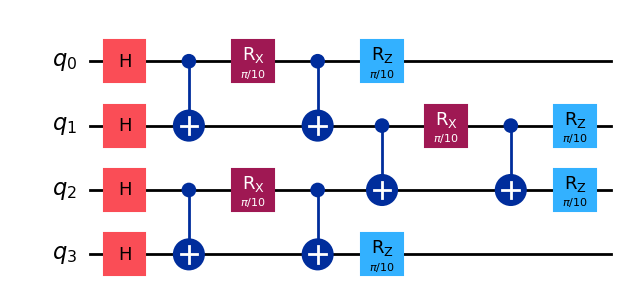

In [21]:
registers = [0, 1, 2, 3]
ising = ps.TransverseIsingModel(quantum_registers=registers)
# circ = ising.second_order_Trotter_unitary()
circ = ising.first_order_Trotter_unitary()
circ.draw('mpl')


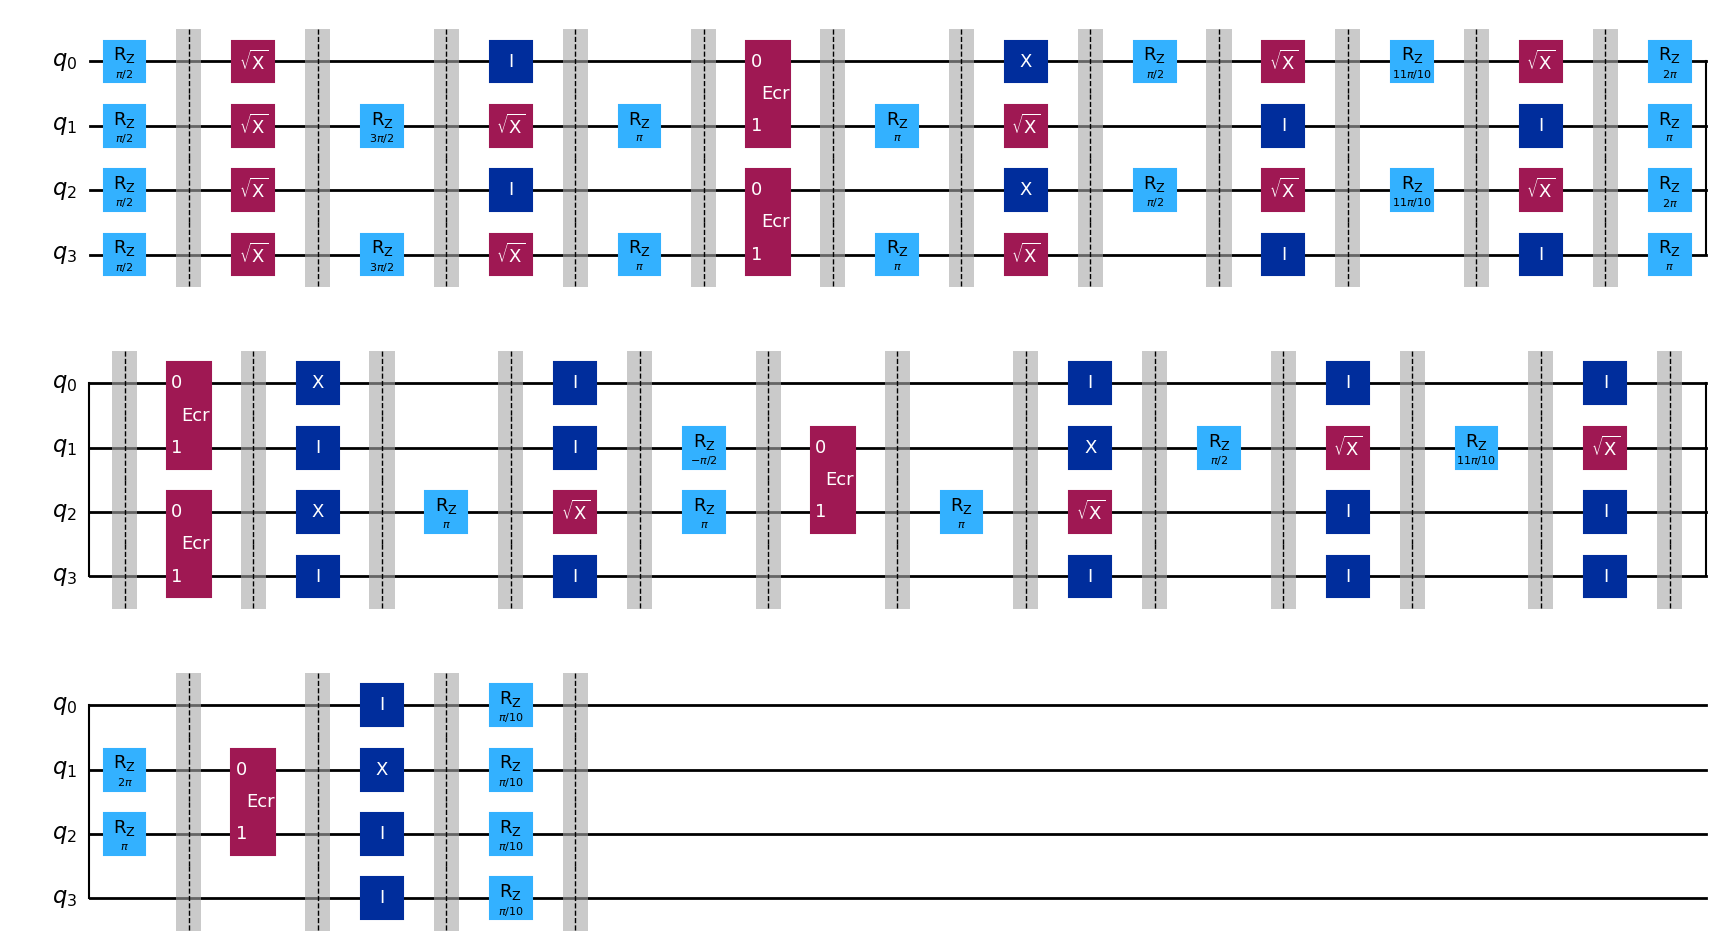

In [22]:
simulator = ps.Simulator(registers, backend)
circ1 = simulator.build_circuit(moments=simulator.build_moments(circ), insert_barriers=True)
circ1.draw("mpl")

#### Remove 2QB

In [ ]:
new_moments = []
for moment in simulator.build_moments(circ):
    if ps.get_moment_case(moment) == "ecr":
        continue
    else:
        new_moments.append(moment)

circ2 = simulator.build_circuit(moments=new_moments, insert_barriers=True)

In [ ]:
# circ1.draw('mpl')
circ2.draw('mpl')

### Random Circuit

In [ ]:
from qiskit.circuit.random import random_circuit

In [ ]:
registers = [0, 1]
simulator = ps.Simulator(registers, backend)

depth = 10
rand_circ = random_circuit(len(registers), depth=depth, seed=17, max_operands=2)
circ3 = simulator.build_circuit(moments=simulator.build_moments(rand_circ), insert_barriers=True)
circ3.draw('mpl')

### Simulataneous XY4

In [191]:
def prepare_state(circ, registers):
    # [circ.h(r) for r in registers]
    [circ.sx(r) for r in registers]

def apply_xy4(circ, q, invert=False):
    circ.x(q)
    circ.y(q)
    circ.x(q)
    circ.y(q)
        
def apply_symmetric_xy4(circ, q):
    # X
    circ.x(q)
    # Y
    circ.rz(-np.pi / 2, q)
    circ.x(q)
    circ.rz(np.pi / 2, q)
    # X
    circ.x(q)
    # Y
    circ.rz(-np.pi / 2, q)
    circ.x(q)
    circ.rz(np.pi / 2, q)

def apply_reverse_xy4(circ, q, invert=False):
    if invert:
        circ.y(q)
        circ.x(q)
        circ.y(q)
        circ.x(q)
    else:
        apply_xy4(circ, q)

def apply_simultaneous_xy4(registers, layers=1, verbose=False):
    circ1 = qk.QuantumCircuit(len(registers))
    circ2 = qk.QuantumCircuit(len(registers))
    circ3 = qk.QuantumCircuit(len(registers))
    prepare_state(circ1, registers)
    prepare_state(circ2, registers)
    prepare_state(circ3, registers)
    for _ in range(layers):
        for r in registers:
            apply_xy4(circ1, r)
            apply_symmetric_xy4(circ2, r)
            apply_reverse_xy4(circ3, r, invert=r%2==0)
    return circ1, circ2, circ3


circXY4_1, circXY4_2, circXY4_3 = apply_simultaneous_xy4([0, 1], layers=50)
circXY4_draw1, circXY4_draw2, circXY4_draw3 = apply_simultaneous_xy4([0, 1], layers=1)

#### Three definitions of Y

In [192]:
c = qk.QuantumCircuit(1)
c.rz(-np.pi / 2, 0)
c.x(0)
c.rz(np.pi / 2, 0)
# c.draw('mpl')
qk.quantum_info.Operator.from_circuit(c)

Operator([[0.00000000e+00+0.j, 2.22044605e-16-1.j],
          [2.22044605e-16+1.j, 0.00000000e+00+0.j]],
         input_dims=(2,), output_dims=(2,))


In [193]:
c = qk.QuantumCircuit(1)
c.rz(-np.pi, 0)
c.x(0)
# c.draw('mpl')
qk.quantum_info.Operator.from_circuit(c)

Operator([[0.000000e+00+0.j, 6.123234e-17-1.j],
          [6.123234e-17+1.j, 0.000000e+00+0.j]],
         input_dims=(2,), output_dims=(2,))


In [194]:
c = qk.QuantumCircuit(1)
c.y(0)
# c.draw('mpl')
qk.quantum_info.Operator.from_circuit(c) 

Operator([[0.+0.j, 0.-1.j],
          [0.+1.j, 0.+0.j]],
         input_dims=(2,), output_dims=(2,))


##### Check fidelities of short circuits

In [195]:
op1 = np.array(qk.quantum_info.Operator.from_circuit(circXY4_draw1).data)
op2 = np.array(qk.quantum_info.Operator.from_circuit(circXY4_draw2).data)
op3 = np.array(qk.quantum_info.Operator.from_circuit(circXY4_draw3).data)

np.isclose(op1, op2), np.isclose(op2, op3), np.isclose(op1, op3)
# ps.operator_fidelity(op1, op2), ps.operator_fidelity(op2, op3), ps.operator_fidelity(op1, op3)

(array([[ True,  True,  True,  True],
        [ True,  True,  True,  True],
        [ True,  True,  True,  True],
        [ True,  True,  True,  True]]),
 array([[ True,  True,  True,  True],
        [ True,  True,  True,  True],
        [ True,  True,  True,  True],
        [ True,  True,  True,  True]]),
 array([[ True,  True,  True,  True],
        [ True,  True,  True,  True],
        [ True,  True,  True,  True],
        [ True,  True,  True,  True]]))

In [196]:
op1

array([[0. +0.5j, 0.5+0.j , 0.5+0.j , 0. -0.5j],
       [0.5+0.j , 0. +0.5j, 0. -0.5j, 0.5+0.j ],
       [0.5+0.j , 0. -0.5j, 0. +0.5j, 0.5+0.j ],
       [0. -0.5j, 0.5+0.j , 0.5+0.j , 0. +0.5j]])

In [197]:
op2

array([[-3.33066907e-16+5.00000000e-01j,  5.00000000e-01+3.33066907e-16j,
         5.00000000e-01+3.33066907e-16j,  3.33066907e-16-5.00000000e-01j],
       [ 5.00000000e-01+0.00000000e+00j,  0.00000000e+00+5.00000000e-01j,
         0.00000000e+00-5.00000000e-01j,  5.00000000e-01+0.00000000e+00j],
       [ 5.00000000e-01+0.00000000e+00j,  0.00000000e+00-5.00000000e-01j,
         0.00000000e+00+5.00000000e-01j,  5.00000000e-01+0.00000000e+00j],
       [-3.33066907e-16-5.00000000e-01j,  5.00000000e-01-3.33066907e-16j,
         5.00000000e-01-3.33066907e-16j,  3.33066907e-16+5.00000000e-01j]])

In [198]:
op3

array([[0. +0.5j, 0.5+0.j , 0.5+0.j , 0. -0.5j],
       [0.5+0.j , 0. +0.5j, 0. -0.5j, 0.5+0.j ],
       [0.5+0.j , 0. -0.5j, 0. +0.5j, 0.5+0.j ],
       [0. -0.5j, 0.5+0.j , 0.5+0.j , 0. +0.5j]])

#### Inspect XY4 RZ placement

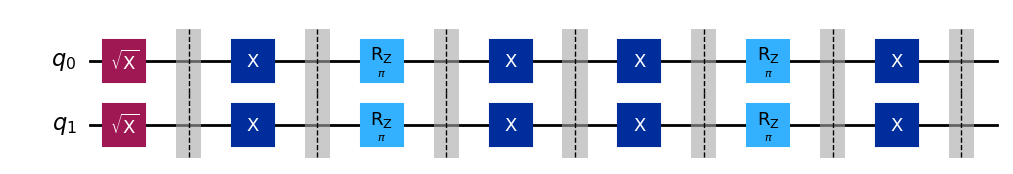

In [159]:
simulator.build_circuit(moments=simulator.build_moments(circXY4_draw1), insert_barriers=True).draw('mpl')

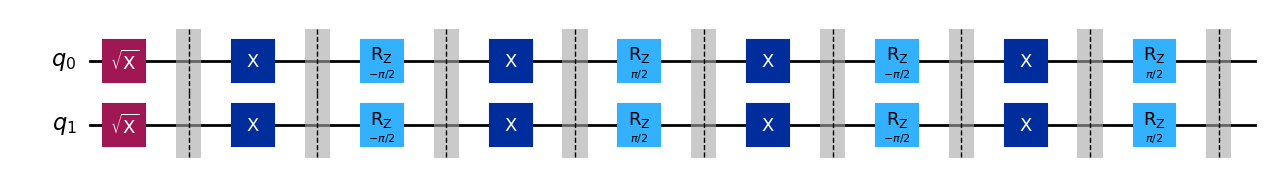

In [160]:
simulator.build_circuit(moments=simulator.build_moments(circXY4_draw2), insert_barriers=True).draw('mpl')

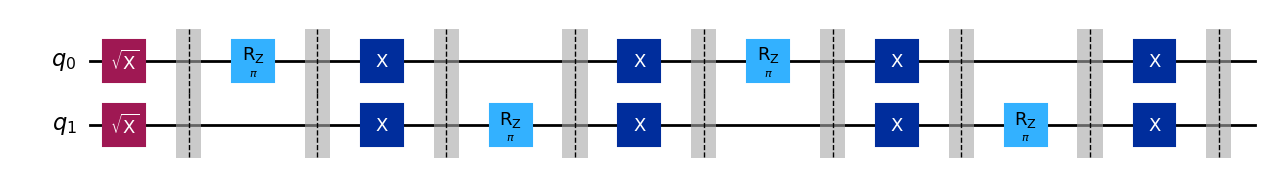

In [161]:
simulator.build_circuit(moments=simulator.build_moments(circXY4_draw3), insert_barriers=True).draw('mpl')

### RB Circuit [[link](https://qiskit-community.github.io/qiskit-experiments/manuals/verification/randomized_benchmarking.html)]

In [ ]:
from qiskit_experiments.library import StandardRB

In [ ]:
registers = [0, 1]#, 2] #, 3]
seeds = [17, 18]#, 19] #, 20]
simulator = ps.Simulator(registers, backend)
simult_rb = qk.QuantumCircuit(len(registers))

for r, seed in zip(registers, seeds):
    # Create an RB experiment
    lengths = [10]
    rb_exp = StandardRB([0], lengths, num_samples=1, seed=seed)
    rb_circ = qk.transpile(rb_exp.circuits()[0], backend, optimization_level=1)

    rb_circ = ps.remove_final_measurement(ps.remove_idle_wires(rb_circ))
    # rb_circ.draw(output="mpl")
    simult_rb.compose(rb_circ, qubits=r, inplace=True)

simult_rb = simulator.build_circuit(moments=simulator.build_moments(simult_rb), insert_barriers=True)
simult_rb.draw('mpl')

# Simulator

In this example, we loop over the one and two qubit gatesets.

You can make changes to the simulator's random variable params between runs, instead of changing the actual simulator variables.

This is because actually using the sampled values for crosstalk required thinking about frequency layouts, which I did not want to do.

It is important to turn on decoherence if we want to see the advantages for the 2QB gate reduction.

In [ ]:
# sampler = ps.BackendSampler(1e9)
# J12 = sampler.frequency_units(sampler.draw_coupling(mean=True), angular=True)
# α = sampler.frequency_units(sampler.draw_anharmonicity(mean=True), angular=True)
# Δ12 = sampler.frequency_units(sampler.draw_frequency(std=True), angular=True)
# 2 * α * J12**2 / (Δ12**2 - α**2) * 1e3 # Note units!

In [ ]:
# angle = ps.two_qubit_models.calibrate_default_cross_resonance_drive(
#     "SWPT", sampler=simulator._backend_sampler
# )

# c_ix = 0.0083
# cal_2qb_rotary = ps.calibrate_gateset(
#     gateset=np.vstack([ecr_a[1, :], -ecr_a[1, :]]),
#     names=["+", "-"],
#     angles=[-angle * c_ix, angle * c_ix],
#     duration=duration_2qb,
#     dt=dt,
#     samples=60,
# )

# cal_2qb_robust = ps.calibrate_gateset(
#     gateset=np.vstack([ecr_a[1, :], -ecr_a[1, :]]),
#     names=["+", "-"],
#     angles=[angle, -angle],
#     duration=duration_2qb,
#     dt=dt,
#     samples=60,
# )

In [ ]:
save_data = False

registers = [0, 1]
circuits = [circXY4_1, circXY4_2, circXY4_3]

total_data = []

for circ_i, circ in enumerate(circuits):

    now = datetime.now()
    dt_string = now.strftime("%Y-%m-%d_%H-%M-%S")
    if len(circuits) > 1:
        dt_string = f"{dt_string}_circ{circ_i}"
    using_two_qubit_gates = False

    simulator = ps.Simulator(registers, backend)
    J_default = simulator._backend_sampler.params["coupling"]["mean"]
    print(f"J default: {J_default}")

    include_crosstalk = True
    include_dissipation = False
    model_name = "SWPT"

    J_inputs = [1.5] # [1.0, 1.5, 2.0, 4.0]  # 1.0, 1.5, 2.0]
    J_results = []

    for J_factor in J_inputs:
        print(f"J factor: {J_factor}")
        # --------------------------------
        simulator._backend_sampler.params["coupling"]["mean"] = J_default * J_factor

        if using_two_qubit_gates:
            # NOTE: 2QB duration should change with J!
            duration_2qb = duration_2qb_default / J_factor
            print(f"\tDuration should change: {duration_2qb}")

            angle = ps.two_qubit_models.calibrate_default_cross_resonance_drive(
                model_name, sampler=simulator._backend_sampler
            )
            print(f"\tAngle should change: {angle}")

            gates_2qb = {"+": angle, "-": -angle}
            cal_2qb = ps.default_gateset(gates_2qb, duration_2qb, dt)

            amplitude = np.max(ps.get_samples(cal_2qb["+"]).real)
            print(f"\tAmplitude should stay the same: {amplitude}")

            # NOTE: this wouldn't actually work on hardware... but it's a start
            c_ix = 0.0083
            cal_2qb_robust = ps.calibrate_gateset(
                gateset=np.vstack([ecr_a[1, :], -ecr_a[1, :]]),
                names=["+", "-"],
                angles=[angle, -angle],
                duration=duration_2qb,
                dt=dt,
                samples=60,
            )

            cal_2qb_rotary = ps.calibrate_gateset(
                gateset=np.vstack([ecr_a[1, :], -ecr_a[1, :]]),
                names=["+", "-"],
                angles=[-angle * c_ix, angle * c_ix],
                duration=duration_2qb,
                dt=dt,
                samples=60,
            )

            rotary_2qb = ps.default_gateset({"+": np.pi, "-": -np.pi}, duration_2qb, dt)

            cases = [
                "1-default, 2-default", 
                "1-robust, 2-default", 
                "1-robust, 2-rotary",
                "1-robust, 2-robust",
            ]
            gateset_pairs = [
                [cal_1qb_default, [cal_2qb, None]],
                [cal_1qb_robust, [cal_2qb, None]],
                [cal_1qb_robust, [cal_2qb, rotary_2qb]],
                [cal_1qb_robust, [cal_2qb_robust, cal_2qb_rotary]],
            ]
        else:
            duration_2qb = duration_2qb_default
            cases = [
                "1-robust", 
                "1-default", 
            ]
            gateset_pairs = [
                [cal_1qb_robust, [None, None]],
                [cal_1qb_default, [None, None]],
            ]

        # --------------------------------

        fidelities = {}

        # Create directory
        if save_data:
            directory = (
                f"../playground/data_{dt_string}/"
                + f"J_{J_factor}_crosstalk_{include_crosstalk}_dissipation_{include_dissipation}"
            )
            os.makedirs(directory)

        for case, pair in zip(cases, gateset_pairs):
            gateset1, gateset2s = pair
            gateset2, rotary2 = gateset2s

            res = simulator.simulate_circuit(
                circ,
                gateset1,
                gateset2,
                dt,
                include_crosstalk=include_crosstalk,
                include_dissipation=include_dissipation,
                insert_identities=True,
                cross_resonance_model_name=model_name,
                gpu=True,
                rotary_gates=rotary2,
                virtual_cases=["phase"]
            )

            moments = simulator.get_moments()

            measure_times = (
                np.cumsum(ps.durations_of_moments(moments, duration_1qb, duration_2qb)) * dt
            )

            U_goals = []
            for i in range(len(moments)):
                U_goals.append(ps.build_operator(moments[0:i+1], registers))

            # skip initial state in result TODO: should we even return it?
            if include_dissipation:
                fids = np.array(
                    [
                        qk.quantum_info.process_fidelity(R, qk.quantum_info.SuperOp(U))
                        for R, U in zip(res[1:], U_goals)
                    ]
                )
            else:
                fids = np.array(
                    [ps.operator_fidelity(R, U) for R, U in zip(res[1:], U_goals)]
                )
            fidelities[case] = fids

            # Save data
            if save_data:
                with open(f"{directory}/fidelities_{case}.pkl", "wb") as f:
                    pkl.dump(fidelities, f)

                with open(f"{directory}/result_{case}.pkl", "wb") as f:
                    pkl.dump(res, f)

        J_results.append(fidelities)

        # Save shared data
        if save_data:
            with open(f"{directory}/measure_times.pkl", "wb") as f:
                pkl.dump(measure_times, f)

    if save_data:
        with open(f"../playground/data_{dt_string}/J_results.pkl", "wb") as f:
            pkl.dump(J_results, f)

    total_data.append(J_results)

J default: 10430087.609918114
J factor: 1.5
J default: 10430087.609918114
J factor: 1.5
J default: 10430087.609918114
J factor: 1.5


#### Do phase moments have errors? No.

In [13]:
## This case was for XY and YX. Fidelity was about 1.0
## -----
phase_moments = [
    simulator.get_moments()[1],
    simulator.get_moments()[3],
]
print(phase_moments)
expected_phase = [ps.build_operator([m], registers) for m in phase_moments]

[ps.operator_fidelity(e,a) for e, a in zip(expected_phase, simulator._unique_results_dict['phase'])]


## This case was for XY and XY. Fidelit was also 1.0
## -----
# phase_moments = [
#     simulator.get_moments()[0],
#     simulator.get_moments()[4],
# ]
# expected_phase = [ps.build_operator([m], registers) for m in phase_moments]

# [ps.operator_fidelity(e,a) for e, a in zip(expected_phase, simulator._unique_results_dict['phase'])]

[{0: 'X', 1: 'X'}, {0: 'X', 1: 'X'}]


[0.0]

In [ ]:
ps.build_operator([m], registers)

In [ ]:
# simulator._unique_results_dict['single'] == saved_single

True

In [243]:
# saved_single_xy_yx = simulator._unique_results_dict['single']
# saved_single_xy_xy = simulator._unique_results_dict['single']
saved_single_xy_xy == saved_single_xy_yx

True

In [ ]:
# simulator.get_schedules()[1].draw()

#### Plots

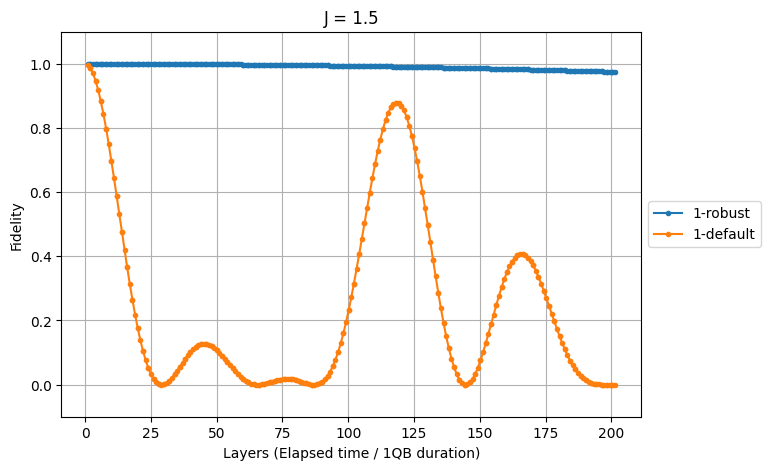

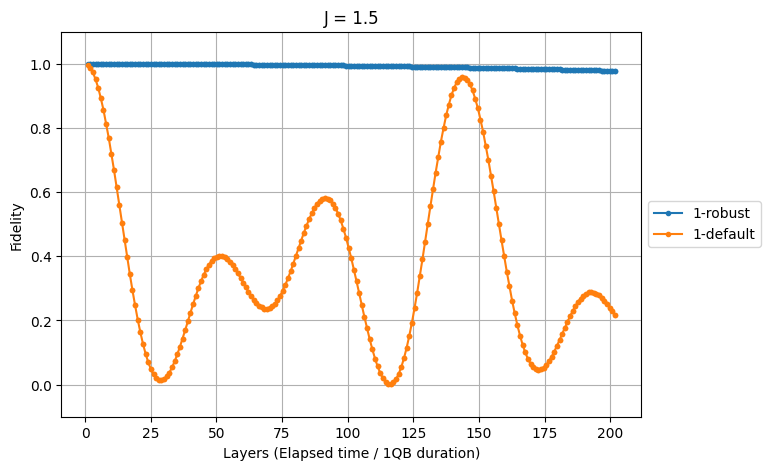

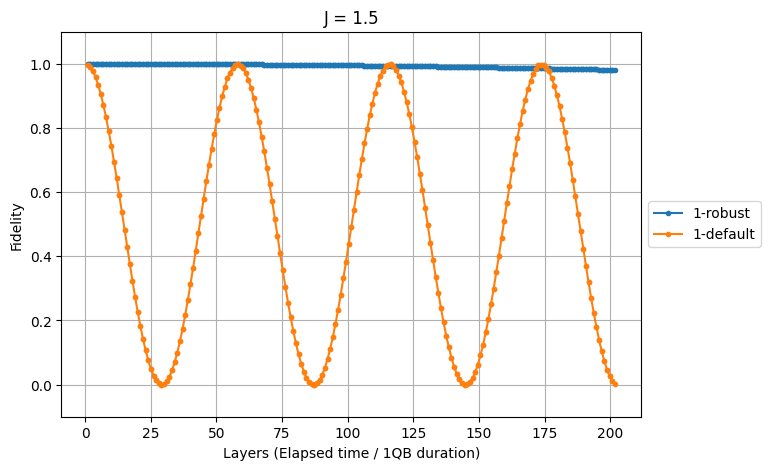

In [176]:
for circ, J_results in zip(circuits, total_data):

    fig, axes = plt.subplots(len(J_results), 1, figsize=(8, 5))
    axes = np.atleast_1d(axes)

    for ax, J, fidelities in zip(axes.flatten(), J_inputs, J_results):
        for case in cases:
            # Don't forget to save or update the measure times
            moments = simulator.build_moments(circ)
            duration_2qb = duration_2qb_default / J
            measure_times = (
                np.cumsum(ps.durations_of_moments(moments, duration_1qb, duration_2qb)) * dt
            )
            ax.plot(measure_times / duration_1qb / dt, fidelities[case], label=case, marker=".")
        ax.set_title(f"J = {J}")
        
        # ax.set_yscale("log")
        ax.set_ylim([-0.1, 1.1])
        # ax.set_xticks(np.arange(0, 18, 1))
        ax.set_xlabel("Layers (Elapsed time / 1QB duration)")
        ax.set_ylabel("Fidelity")
        ax.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
        # ax.set_yticks(np.arange(0, 0.4, 0.1))
        ax.grid(True)

    fig.subplots_adjust(hspace=1.25, right=0.85)
    plt.show()

## The standard plot

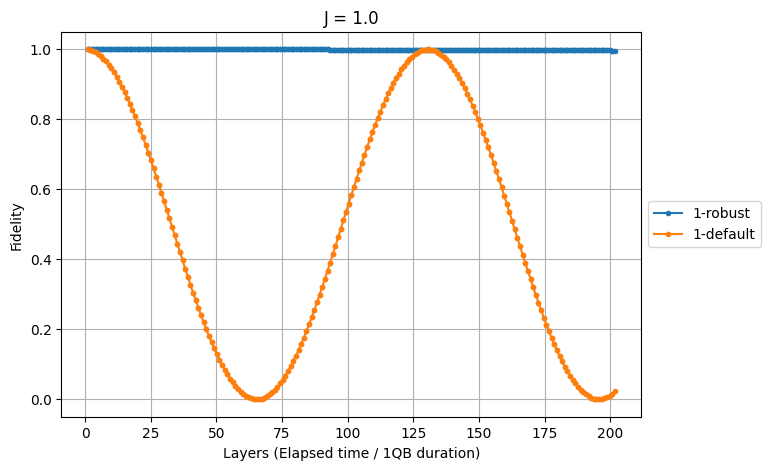

In [ ]:
fig, axes = plt.subplots(len(J_results), 1, figsize=(8, 5))
axes = np.atleast_1d(axes)

for ax, J, fidelities in zip(axes.flatten(), J_inputs, J_results):
    for case in cases:
        # Don't forget to save or update the measure times
        duration_2qb = duration_2qb_default / J
        measure_times = (
            np.cumsum(ps.durations_of_moments(moments, duration_1qb, duration_2qb)) * dt
        )
        ax.plot(measure_times / duration_1qb / dt, fidelities[case], label=case, marker=".")
    ax.set_title(f"J = {J}")
    
    # ax.set_yscale("log")
    # ax.set_xticks(np.arange(0, 18, 1))
    ax.set_xlabel("Layers (Elapsed time / 1QB duration)")
    ax.set_ylabel("Fidelity")
    ax.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
    # ax.set_yticks(np.arange(0, 0.4, 0.1))
    ax.grid(True)

fig.subplots_adjust(hspace=1.25, right=0.85)

In [418]:
simulator._solver_kwargs

{'backend_sampler': <pulse_simulator.models.qiskit_backend_utils.BackendSampler at 0x7bc0633165a0>,
 'include_crosstalk': True,
 'include_dissipation': False,
 'simulation_vars': {'t1q0': 200843.02984128593,
  't1q1': 209515.46320390716,
  't2q0': 154152.83398606293,
  't2q1': 146848.321128537,
  'wq0': 5.021138869885644,
  'wq1': 4.93722744043108,
  'jq0q1': 0.00166,
  'delta0': -0.31291584618236895,
  'delta1': -0.31680530602700313,
  'omegad0': 0.15915494309189535,
  'omegad1': 0.15915494309189535},
 'simulation_dt': 0.5,
 'cross_resonance_model_name': 'SWPT'}

## Other Plots

In [ ]:
# Extract final fidelities for each case and J value
cases = J_results[0].keys()
final_kl = {case: [] for case in cases}
for fidelities in J_results:
    for case in cases:
        final_kl[case].append(fidelities[case][-1])

# Create the bar chart
fig, ax = plt.subplots(figsize=(10, 6))

bar_width = 0.2
x = np.arange(len(J_inputs))

for i, case in enumerate(cases):
    ax.bar(x + i * bar_width, final_kl[case], bar_width, label=case)

ax.set_xlabel('J values')
ax.set_ylabel('Final Fidelity')
ax.set_title('TFIM Final Fidelity for Different Cases and J Values')
ax.set_xticks(x + bar_width)
ax.set_xticklabels(J_inputs)
ax.set_ylim([0, 1])
ax.legend()

In [ ]:
# with open("../playground/data_2024-10-29_22-38-03/J_results.pkl", "rb") as file:
#     J_results_prev = pkl.load(file)

# J_results_new = []
# for prev, current in zip(J_results_prev, J_results):
#     J_results_new.append({**prev, **current})

In [ ]:
# J_results_newer = J_results + J_results_new

In [ ]:
J_inputs = [0.5, 1.0, 1.5, 2.0, 4.0]

# Extract final fidelities for each case and J value
cases = J_results_newer[0].keys()
final_kl = {case: [] for case in cases}
for fidelities in J_results_newer:
    for case in cases:
        final_kl[case].append(fidelities[case][-1])

# Define a professional color palette using matplotlib's colormap
colors = cm.get_cmap('tab10').colors

# Define patterns for the bars
patterns = ['/', '\\', 'x', '-', '.', '*']

# Create the bar chart
fig, ax = plt.subplots(figsize=(11, 4))

# Add horizontal gridlines
ax.yaxis.grid(True)

# Move the grid to the background
ax.set_axisbelow(True)

# Adjust bar width and spacing
bar_width = 0.1
group_spacing = 0.4
x = np.arange(len(J_inputs)) * (len(cases) * bar_width + group_spacing)

for i, (case, color, pattern) in enumerate(zip(cases, colors, patterns)):
    ax.bar(x + i * bar_width, final_kl[case], bar_width, label=case, color=color, hatch=pattern)

ax.set_xlabel('J values')
ax.set_ylabel('Final Fidelity')
ax.set_title('TFIM Final Fidelity for Different Cases and J Values')
ax.set_xticks(x + bar_width * (len(cases) - 1) / 2)
ax.set_xticklabels(J_inputs)
ax.legend()
ax.set_ylim([0, 1])
ax.set_yticks(np.arange(0, 1.1, 0.1))
plt.show()

In [ ]:
# need the expected distribution for KL divergence
x = ps.qiskit_ground_state(4).evolve(U_goals[-1])
y_expected = np.abs(x.data) ** 2

loc = (
    lambda x: f"../playground/data_2024-10-29_22-38-03/J_{x}_crosstalk_True_dissipation_True/"
)

kl_divergences = []
for J in ["1.0", "1.5", "2.0", "4.0"]:
    kl_entry = {}
    for case in ["1-default, 2-default", "1-robust, 2-default", "1-robust, 2-rotary"]:
        with open(loc(J) + f"result_{case}.pkl", "rb") as file:
            J_results_1 = pkl.load(file)
            x = ps.qiskit_ground_state(4, open=True).evolve(J_results_1[-1])
            y_actual = x.probabilities(qargs=[0, 1, 2, 3])
            kl_entry[case] = np.sum(
                [yp * np.log(yp / yq) for yq, yp in zip(y_expected, y_actual)]
            )
    kl_divergences.append(kl_entry)

loc = (
    lambda x: f"../playground/data_2024-10-30_21-03-37/J_{x}_crosstalk_True_dissipation_True/"
)

for i, J in enumerate(["1.0", "1.5", "2.0", "4.0"]):
    for case in ["1-robust, 2-robust"]:
        with open(loc(J) + f"result_{case}.pkl", "rb") as file:
            J_results_1 = pkl.load(file)
            x = ps.qiskit_ground_state(4, open=True).evolve(J_results_1[-1])
            y_actual = x.probabilities(qargs=[0, 1, 2, 3])
            kl_divergences[i][case] = np.sum(
                [yp * np.log(yp / yq) for yq, yp in zip(y_expected, y_actual)]
            )

loc = (
    lambda x: f"../playground/data_2024-10-30_23-08-07/J_{x}_crosstalk_True_dissipation_True/"
)

for i, J in enumerate(["0.5"]):
    kl_entry = {}
    for case in ["1-default, 2-default", "1-robust, 2-default", "1-robust, 2-rotary", "1-robust, 2-robust"]:
        with open(loc(J) + f"result_{case}.pkl", "rb") as file:
            J_results_1 = pkl.load(file)
            x = ps.qiskit_ground_state(4, open=True).evolve(J_results_1[-1])
            y_actual = x.probabilities(qargs=[0, 1, 2, 3])
            kl_entry[case] = np.sum(
                [yp * np.log(yp / yq) for yq, yp in zip(y_expected, y_actual)]
            )
kl_divergences = [kl_entry] + kl_divergences

In [ ]:
J_inputs = [0.5, 1.0, 1.5, 2.0, 4.0]

# Extract final fidelities for each case and J value
final_kl = kl_divergences[0].keys()
final_kl = {case: [] for case in cases}
for kls in kl_divergences:
    for case in cases:
        final_kl[case].append(kls[case])

# Define a professional color palette using matplotlib's colormap
colors = cm.get_cmap('tab10').colors

# Define patterns for the bars
patterns = ['/', '\\', 'x', '-', '.', '*']

# Create the bar chart
fig, ax = plt.subplots(figsize=(11, 4))

# Add horizontal gridlines
ax.yaxis.grid(True)

# Move the grid to the background
ax.set_axisbelow(True)

# Adjust bar width and spacing
bar_width = 0.1
group_spacing = 0.4
x = np.arange(len(J_inputs)) * (len(cases) * bar_width + group_spacing)

for i, (case, color, pattern) in enumerate(zip(cases, colors, patterns)):
    ax.bar(x + i * bar_width, final_kl[case], bar_width, label=case, color=color, hatch=pattern)

ax.set_xlabel('J values')
ax.set_ylabel('KL Divergence')
ax.set_title('TFIM Final KL Divergence for Different Cases and J Values')
ax.set_xticks(x + bar_width * (len(cases) - 1) / 2)
ax.set_xticklabels(J_inputs)
ax.legend()
# ax.set_ylim([5e-4, 2])
# ax.set_yscale("log")
# ax.set_yticks(np.arange(-0.1, 0.5, 0.1))
plt.show()